In [88]:
#installation des dependances

import numpy as np
import netCDF4 as nc4                 # librarie pour lire les fichiers ***.nc (sinon xarray est plus performante)
import matplotlib.pyplot as plt        # librairie pour les graphiques 
import matplotlib as mpl
from matplotlib.colors import BoundaryNorm
import os                                        # accès aux commande système
import sys, getopt                          # gestion des entrées sorties 
import xarray as xr


In [104]:
dx = 10
domx = 864

In [150]:
def read_1D_exp(file_path, variable_name='tn', timeindex=-1, dmax=87):
    endtoce = None
    try:
        dataset = xr.open_dataset(file_path)[variable_name]
        coupe = int(dataset['y_grid_T'].max()//2)
        print("y = ", coupe)
        endtoce = dataset.isel(time_counter=-2, deptht=0, y_grid_T = coupe) #-2 car on veut regarder le 20e jour et pas le 21e
        #endtoce = dataset.variables[variable_name][timeindex,:,:,0]
        dataset.close()
        #print(endtoce.shape)
    except FileNotFoundError as e:
        print(f"File not found: {e.filename}")
    return endtoce


# Simple plots
def convergence(repo_name='', dmax=87, lab='', var='soce', type=1) :
    tmean = []
    trmse = []
    tmax = []


    Dxs = [ 12, 18, 24]

    fig, ax = plt.subplots(1, 2, figsize=(12,7))
    
    for i,iDx in enumerate(Dxs):
        ilab = str(iDx)
        print('Calcul pour dx ='+ilab)
        iend = format(int(48*3600/iDx), '08d')

        file_path = repo_name+ 'CANAL_gauss_ubs'+ilab+'_all_grid.nc' 
        print('Ouverture de la reference')
        ref = read_1D_exp(repo_name + 'CANAL_gauss_traadvOFF'+ilab+'_all_grid.nc' , variable_name=var, dmax=dmax)
        print(file_path)
        print('Ouverture du schema ubs'+ilab) 
        diff = read_1D_exp(file_path, variable_name=var, dmax=dmax) - ref
        dep = np.arange(diff.shape[0])
        #plt.plot(dep, diff, label=ilab)
        #plt.show()
        #print(f"Differents calcul d'erreurs, erreur moyenne : {np.mean(diff)}, derniere erreur {diff[-1]}, variance de l'erreur {np.sqrt(np.mean(diff**2))}")
        tmean.append(np.mean(abs(diff)))
        trmse.append(np.sqrt(np.mean(diff**2)))
        tmax.append(abs(diff).max())
    #print(f'###############################tmean : {tmean}, trmse : {trmse}')
        
        
    
    # --- Ligne 0 : erreur moyenne (tmean) ---
    ax[0].loglog(Dxs, tmean, '.-', label = 'erreur tmean mesuree')
    #ax[0][0].set_title('Mesuré')
    
    ax[0].loglog(Dxs, [dx**2/Dxs[0]**2*tmean[0] for dx in Dxs], '.-', label = 'Ordre 2')
    #ax[0].set_title('Ordre 2 (théorique)')
    
    ax[0].loglog(Dxs, [dx/Dxs[0]*tmean[0] for dx in Dxs], '.-', label = 'Ordre 1')
    #ax[0][2].set_title('Ordre 1 (théorique)')
    plt.legend()
    # --- Ligne 1 : RMSE (trmse) ---
    ax[1].loglog(Dxs, trmse, '.-', label = 'erreur trmse mesuree')
    ax[1].loglog(Dxs, [dx**2/Dxs[0]**2*trmse[0] for dx in Dxs], '.-', label = 'Ordre 2')
    ax[1].loglog(Dxs, [dx/Dxs[0]*trmse[0] for dx in Dxs], '.-', label = 'Ordre 1')
    
    # --- Mise en forme commune ---
    for i in range(1):
        ax[i].grid(True, color='0.95')
        ax[i].set_xlabel('Dx')
        ax[i].set_xticks(Dxs)
        ax[i].set_xticklabels(Dxs)

    ax[0].set_ylabel('Error tmean')
    ax[1].set_ylabel('Error trmse')
    
    
    fig.suptitle('C1D ' + lab)
    plt.legend()
    plt.tight_layout()
    
    # plt.savefig(path_cfgs + '/' + os.environ['PWD'].split('/')[-2] + '_Conv_' + sys.argv[1] + '_' + sys.argv[2])
    plt.show()

    return tmean, trmse


Calcul pour dx =12
Ouverture de la reference
y =  41
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/CANAL_gauss_ubs12_all_grid.nc
Ouverture du schema ubs12
y =  41
Calcul pour dx =18
Ouverture de la reference
y =  28
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/CANAL_gauss_ubs18_all_grid.nc
Ouverture du schema ubs18
y =  28
Calcul pour dx =24
Ouverture de la reference
y =  21
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/CANAL_gauss_ubs24_all_grid.nc
Ouverture du schema ubs24
y =  21


/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_30466/1602803090.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


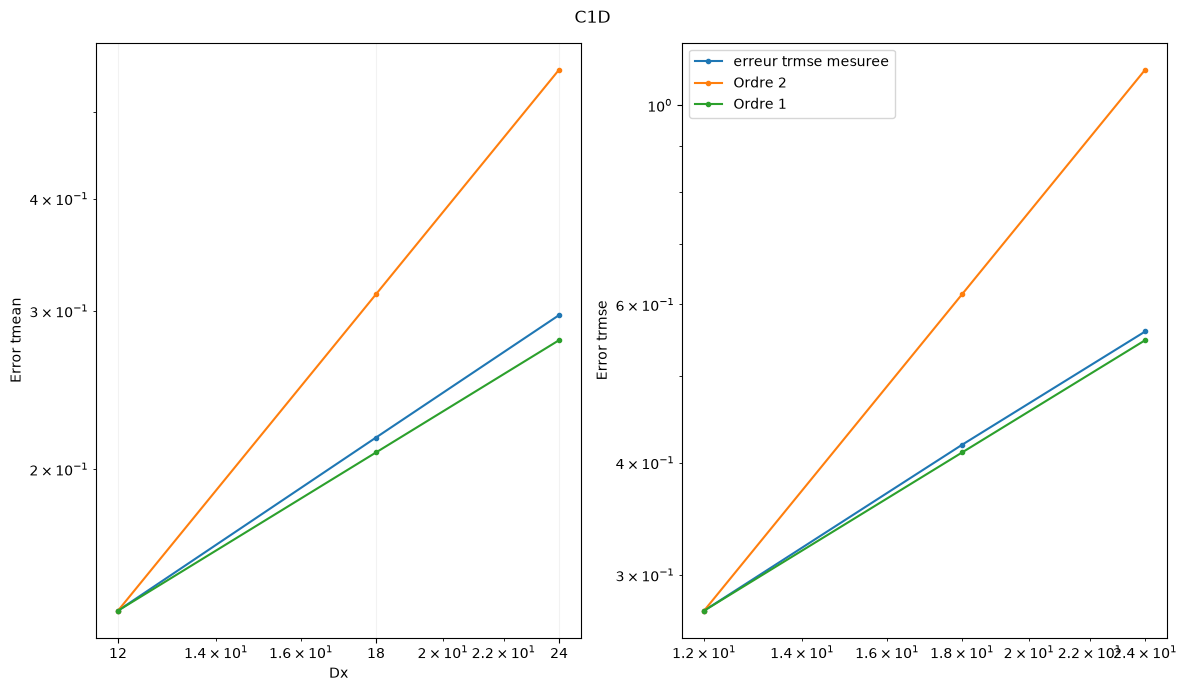

In [151]:
tmean, trmse = convergence(repo_name='/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/', dmax=87, lab='', var='soce', type=1) 


In [152]:
from scipy import stats
Dxs = [ 12, 18, 24]
regress = stats.linregress(np.log(Dxs), np.log(trmse))

In [153]:
pente = regress[0]
origine = regress[1]
# On peut alors afficher les valeurs de ces deux paramètres
print(f'Pente = {pente} et Origine = {origine}')

Pente = 1.0332919662397422 et Origine = -3.8613596228016576


Calcul pour dx =12
Ouverture de la reference
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/CANAL_gauss_ubs12_all_grid.nc
Ouverture du schema
Calcul pour dx =18
Ouverture de la reference
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/CANAL_gauss_ubs18_all_grid.nc
Ouverture du schema
Calcul pour dx =24
Ouverture de la reference
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/CANAL_gauss_ubs24_all_grid.nc
Ouverture du schema


Text(0, 0.5, 'Valeur de la salinite au point x= 18, y= 21')

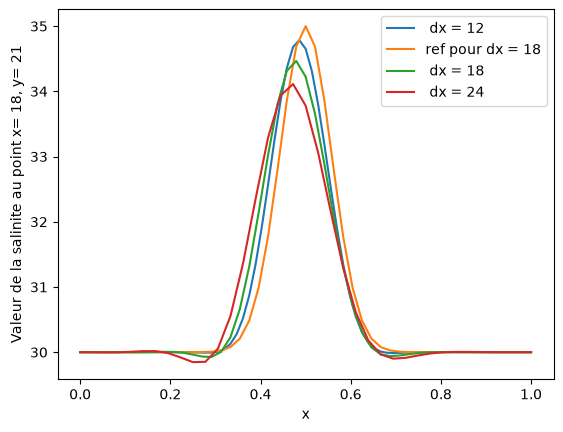

In [155]:
Dxs =[12, 18, 24]
repo_name='/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/'


for i,iDx in enumerate(Dxs):
        if iDx== 18 : 
            ref = xr.open_dataset(repo_name + 'CANAL_gauss_traadvOFF18_all_grid.nc')['soce']
            ref = ref.isel(time_counter=-1, y_grid_T = 1, deptht=0)
            dep = [i*iDx/domx for i in range (ref.shape[0])]
            plt.plot(dep, ref, label=f"ref pour dx = {iDx}")
            
        ilab = str(iDx)
        print('Calcul pour dx ='+ilab)
        iend = format(int(48*3600/iDx), '08d')

        file_path = repo_name+ 'CANAL_gauss_ubs'+ilab+'_all_grid.nc' 
        print('Ouverture de la reference')
    #ouverture des donnees
        print(file_path)

        dataset = xr.open_dataset(file_path)['soce']
        ymid, xmid = int(dataset['y_grid_T'].max()//2), int(dataset['x_grid_T'].max()//2)

        data = dataset.isel(time_counter=-2, y_grid_T = 1, deptht=0) #-2 car on veut regarder le 20e jour et pas le 21e
        print('Ouverture du schema') 
        dep = [i*iDx/domx for i in range (data.shape[0])]
        plt.plot(dep, data, label=f" dx = {ilab}")

plt.legend()
plt.xlabel('x')
plt.ylabel(f"Valeur de la salinite au point x= {xmid}, y= {ymid}")
    

